IMPORT LIBRARIES


In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(ConfusionMatrixDisplay,
    accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,
    classification_report,roc_auc_score,roc_curve
)

In [3]:
df=pd.read_csv(r"C:\Users\HP\Desktop\Machine Learning 1\Project1_bike_Price\project2_loan_datasets\Loan_default.csv")

In [4]:
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [5]:
df.tail()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0
255346,ZTH91CGL0B,62,22418,18481,636,113,2,6.73,12,0.48,Bachelor's,Unemployed,Divorced,Yes,No,Education,Yes,0


In [6]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [8]:
df.duplicated().sum()

0

<Axes: xlabel='Default'>

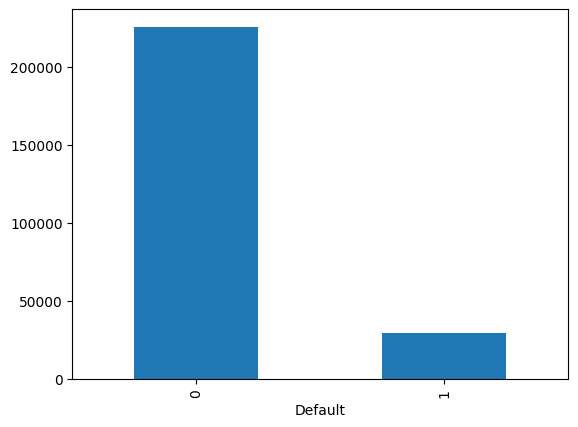

In [10]:
df['Default'].value_counts().plot(kind='bar')

In [ ]:
df.select_dtypes(exclude='object').columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Default'],
      dtype='object')

C:\Users\HP\AppData\Local\Temp\ipykernel_25924\2315175725.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[index].set_xticklabels(['No Default','Default'])


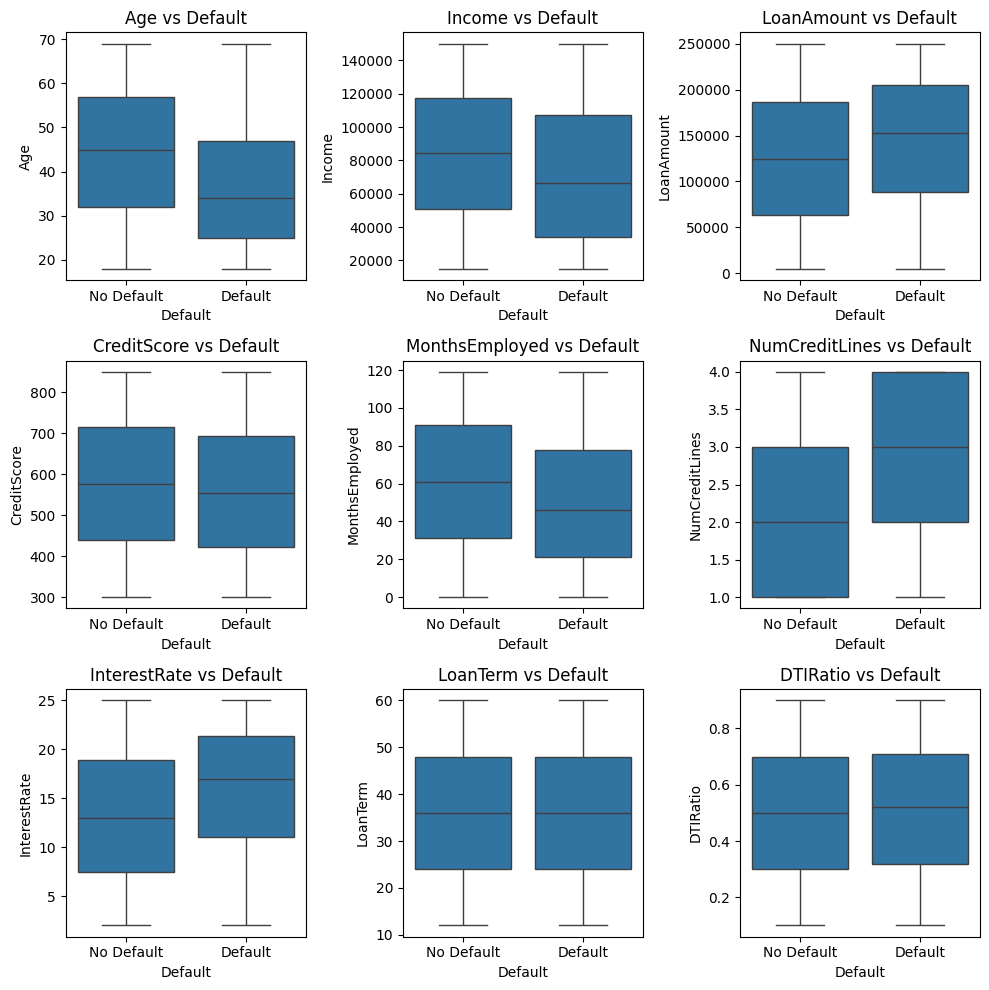

In [17]:
numerical_cols=['Age','Income','LoanAmount','CreditScore','MonthsEmployed','NumCreditLines','InterestRate',
                'LoanTerm','DTIRatio']

fig , axs=plt.subplots(3,3,figsize=(10,10))
axs=axs.flatten()
for index , column_name in enumerate(numerical_cols):
    sns.boxplot(data=df,y=column_name,x='Default',ax=axs[index])
    axs[index].set_title(f'{column_name} vs Default')
    axs[index].set_xticklabels(['No Default','Default'])
    plt.tight_layout()
    
    import warnings 
    warnings.filterwarnings('ignore')

CORRELATION

In [18]:
plt.figure(figsize=(10,8))
df[numerical_cols+['Default']].corr()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
Age,1.000000,-0.001244,-0.002213,-0.000548,-0.000341,-0.000890,-0.001127,0.000263,-0.004689,-0.167783
Income,-0.001244,1.000000,-0.000865,-0.001430,0.002675,-0.002016,-0.002303,-0.000998,0.000205,-0.099119
LoanAmount,-0.002213,-0.000865,1.000000,0.001261,0.002817,0.000794,-0.002291,0.002538,0.001122,0.086659
CreditScore,-0.000548,-0.001430,0.001261,1.000000,0.000613,0.000016,0.000436,0.001130,-0.001039,-0.034166
MonthsEmployed,-0.000341,0.002675,0.002817,0.000613,1.000000,0.001267,0.000096,-0.001166,0.001765,-0.097374
NumCreditLines,-0.000890,-0.002016,0.000794,0.000016,0.001267,1.000000,-0.000297,-0.000226,-0.000586,0.028330
InterestRate,-0.001127,-0.002303,-0.002291,0.000436,0.000096,-0.000297,1.000000,0.000892,0.000575,0.131273
LoanTerm,0.000263,-0.000998,0.002538,0.001130,-0.001166,-0.000226,0.000892,1.000000,0.002273,0.000545
DTIRatio,-0.004689,0.000205,0.001122,-0.001039,0.001765,-0.000586,0.000575,0.002273,1.000000,0.019236
Default,-0.167783,-0.099119,0.086659,-0.034166,-0.097374,0.028330,0.131273,0.000545,0.019236,1.000000


<Figure size 1000x800 with 0 Axes>

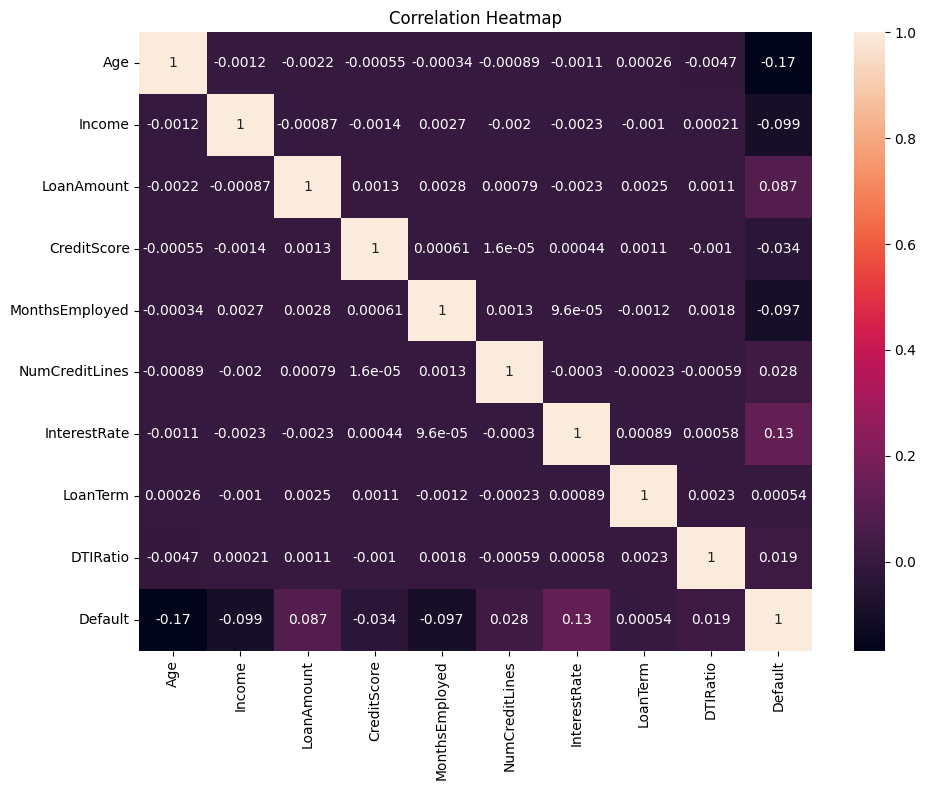

In [19]:
plt.figure(figsize=(10,8))
sns.heatmap(df[numerical_cols+['Default']].corr(),annot=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [21]:
df.drop('LoanID',axis=1,inplace=True)

In [26]:
print(df.columns.tolist())

['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


In [28]:
X=df.drop('Default',axis=1)
Y=df['Default']

In [ ]:
categorical_column=X.select_dtypes(include='object').columns.to_list()
numerical_column=X.select_dtypes(exclude='object').columns.to_list()
label_encoders={}

for col in categorical_column:
    le= LabelEncoder()
    X[col]=le.fit_transform(X[col].astype(str))
    print(f'''encoded{col}:{dict(zip(le.classes_,le.transform(le.classes_)))}''')



encodedEducation:{"Bachelor's": 0, 'High School': 1, "Master's": 2, 'PhD': 3}
encodedEmploymentType:{'Full-time': 0, 'Part-time': 1, 'Self-employed': 2, 'Unemployed': 3}
encodedMaritalStatus:{'Divorced': 0, 'Married': 1, 'Single': 2}
encodedHasMortgage:{'No': 0, 'Yes': 1}
encodedHasDependents:{'No': 0, 'Yes': 1}
encodedLoanPurpose:{'Auto': 0, 'Business': 1, 'Education': 2, 'Home': 3, 'Other': 4}
encodedHasCoSigner:{'No': 0, 'Yes': 1}


In [34]:
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=22
)

In [35]:
scaler=StandardScaler()
X_train_scaled=x_train.copy()
X_test_scaled=x_test.copy()
X_train_scaled[numerical_cols]=scaler.fit_transform(x_train[numerical_column])
X_test_scaled[numerical_cols]=scaler.fit_transform(x_test[numerical_column])

In [36]:
lr=LogisticRegression(class_weight='balanced',
max_iter=100,solver='saga',n_jobs=-1)
lr.fit(X_train_scaled,y_train)
y_pred=lr.predict(X_test_scaled)
y_pred_prob=lr.predict(X_test_scaled)

In [37]:
print(f'accuracy_score:{accuracy_score(y_test,y_pred)}')
print(f'precision_score:{precision_score(y_test,y_pred)}')
print(f'recall_score:{recall_score(y_test,y_pred)}')
print(f'f1_score:{f1_score(y_test,y_pred)}')
print(f'roc_auc_score:{roc_auc_score(y_test,y_pred)}')

accuracy_score:0.6736440180144899
precision_score:0.21708335535704848
recall_score:0.6888627977188863
f1_score:0.33013142558578834
roc_auc_score:0.6802476620500081


In [38]:
print(classification_report(y_test,y_pred,target_names=['No Default','Default']))


              precision    recall  f1-score   support

  No Default       0.94      0.67      0.78     45108
     Default       0.22      0.69      0.33      5962

    accuracy                           0.67     51070
   macro avg       0.58      0.68      0.56     51070
weighted avg       0.86      0.67      0.73     51070



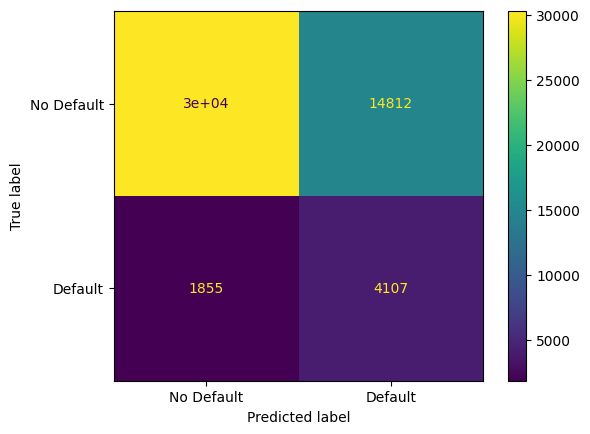

In [39]:
cm=confusion_matrix(y_test,y_pred)
dis=ConfusionMatrixDisplay(confusion_matrix=cm,
display_labels=['No Default','Default'])
dis.plot()
plt.show()

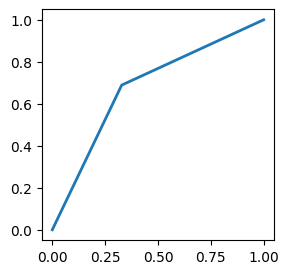

In [40]:
fpr,tpr,thresolds=roc_curve(y_test,y_pred_prob)
plt.figure(figsize=(3,3))
plt.plot(fpr,tpr,lw=2)

In [41]:
lr.coef_

array([[-0.59090717, -0.31145592,  0.28525747, -0.12189698, -0.34010289,
         0.0930658 ,  0.45878648, -0.0018013 ,  0.0657753 , -0.07007945,
         0.12791569, -0.02995536, -0.1573691 , -0.23825124, -0.02905853,
        -0.26217811]])

In [43]:
coef_df=pd.DataFrame({
    'Columns':x_train.columns,
    'cofficient':lr.coef_[0]
}).sort_values(by='cofficient',key=abs,ascending=False)

In [44]:
coef_df

,Columns,cofficient
0,Age,-0.590907
6,InterestRate,0.458786
4,MonthsEmployed,-0.340103
1,Income,-0.311456
2,LoanAmount,0.285257
15,HasCoSigner,-0.262178
13,HasDependents,-0.238251
12,HasMortgage,-0.157369
10,EmploymentType,0.127916
3,CreditScore,-0.121897


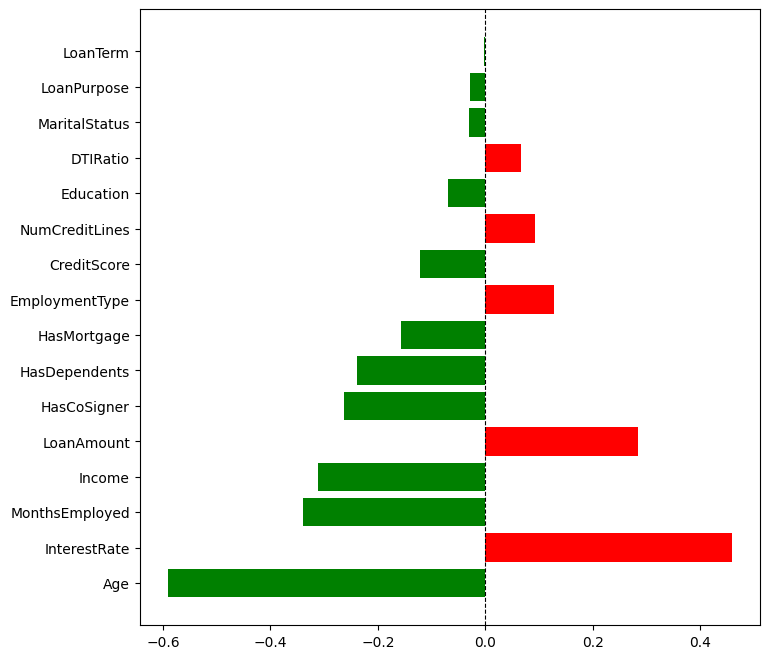

In [ ]:
plt.figure(figsize=(8, 8))
color = ['red' if c > 0 else 'green' for c in coef_df['cofficient']]
plt.barh(coef_df['Columns'], coef_df['cofficient'], color=color)
plt.axvline(x=0, color='black', linewidth=0.8, linestyle='--')
plt.show()

In [49]:
import joblib 
joblib.dump(lr,'logistic_regression.pkl')

['logistic_regression.pkl']

In [50]:
model=joblib.load('logistic_regression.pkl')

In [51]:
model.predict(x_test.iloc[:2,:])

array([1, 1], dtype=int64)